In [1]:
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

In [2]:
faces = fetch_olivetti_faces()
X_train, X_test, y_train, y_test = train_test_split(
    faces.data.astype(np.float64), faces.target,
    test_size=0.3, stratify=faces.target, random_state=0)

In [3]:
mu = X_train.mean(axis=0) # mean face, length 4096. This basically means that we are computing the average pixel value for each pixel across all training images.
A = (X_train - mu).T # m x n = 4096 x 280, columns are centred images.
U, s, Vt = np.linalg.svd(A, full_matrices=False) # The SVD of A. U contains the left singular vectors (eigenfaces), s contains the singular values, and Vt contains the right singular vectors.

In [4]:
print("size of A:", A.shape) # 4096 x 280

size of A: (4096, 280)


In [5]:
print("Shape of U:", U.shape) # 4096 x 280

Shape of U: (4096, 280)


# B2.1 How many singular values? 
What is the largest possible number of nonzero singular values of A? Explain why it is at most $n − 1$ rather than $n$. 
> (Hint: what do the columns of A add up to?) Check your answer numerically.

In [6]:
# Check if the columns add up to 0
col_sum = A.sum(axis=1)
print(np.abs(col_sum).max())

3.697042672001771e-14


In [7]:
# Check A @ 1 = 0 (The columns are linearly dependent, they sum to zero)
ones = np.ones(A.shape[1])
print(np.linalg.norm(A @ ones))

6.273019389623839e-13


In [8]:
# Check how many singular values are actually non-zer0
print(s[-3:])
print(np.sum(s > 1e-10))

[9.92660438e-01 9.30601186e-01 2.87793603e-14]
279


The largest possible number of non-zero singular values of $A$ is $279$. The number of non-zero singular values is the rank of $A$,- which is the maximum number of linearly independent columns. Because $A$ has $280$ columns, and each column is one face minus the average (mean) of all of the faces ($280$), adding up all of the columns will make the faces cancel with the mean, resulting in the zero vector. This means that the columns are linearly dependent. Any one column can be written as minus the sum of the other $279$. Thus, at most $279$ columns are independent, which gives $rank(A) \leq 279$.

# B2.2 Computing the eigenfaces efficiently. 
The principal components are the eigenvectors of $S = AA^T / (n − 1)$, but the SVD procedure from class works through $A^TA$ instead.

#### a) Give the sizes of $AA^T$ and $A^TA$ for the faces. Explain why following the class procedure (orthonormal eigenvectors $v_k$ of $A^TA$, then $u_k = Av_k/\sigma _k)$ is much cheaper than finding the eigenvectors of $S$ directly. Which route would be cheaper for MNIST, and why?

In [9]:
A = (X_train - mu).T

In [10]:
print("A shape:", A.shape)
print("AA^T shape:", (A @ A.T).shape)
print("A^T A shape:", (A.T @ A).shape)

A shape: (4096, 280)
AA^T shape: (4096, 4096)
A^T A shape: (280, 280)


$AA^T$ has a size of $4096 \times 4096$, and $A^TA$ has a size of $280 \times 280$. Following the class procedure (orthonormal eigenvectors $v_k$ of $A^TA$, then $u_k = Av_k/\sigma _k)$ is cheaper than directly finding the eigenvectors of $S$ directly becuause eigenvalue decomposition scales cubically $O(N^3)$ with the matrix dimension. Applying this we can see that $280^3 < 4096^3$. 
The route cheaper for images in the standard MNIST dataset would be the direct route. For MNIST, $m = 784$ and $n = 10,000$, meaning $AA^T$ is $784 \times 784$ while $A^TA$ is $10,000 \times 10,000$.

#### b) Find an eigenvector of $A^TA$ with eigenvalue $0$ and explain why it must exist. Why can’t it be used to produce a principal component?

In [11]:
ATA = A.T @ A

In [12]:
eigenvalues, eigenvectors = np.linalg.eigh(ATA)

zero_mask = np.isclose(eigenvalues, 0, atol=1e-9) # Create a mask identifying eigenvalues that are essentially 0

In [13]:
zero_eigenvectors = eigenvectors[:, zero_mask]

In [14]:
print("Eigenvalues found:\n", eigenvalues)
print("\nIsolated Eigenvector(s) for lambda = 0:\n", zero_eigenvectors)

Eigenvalues found:
 [4.01124579e-16 8.66018567e-01 9.85374745e-01 1.13315883e+00
 1.21750023e+00 1.32669972e+00 1.36899322e+00 1.39427650e+00
 1.42723713e+00 1.47018937e+00 1.51229823e+00 1.56508487e+00
 1.60789704e+00 1.67750117e+00 1.74190156e+00 1.77005679e+00
 1.78441627e+00 1.82723894e+00 1.84026101e+00 1.92624780e+00
 1.95264920e+00 1.99894946e+00 2.01788419e+00 2.03982378e+00
 2.11757543e+00 2.12853116e+00 2.16875384e+00 2.17486629e+00
 2.27650920e+00 2.30871852e+00 2.39011714e+00 2.42681483e+00
 2.47269239e+00 2.48420260e+00 2.54640919e+00 2.56675129e+00
 2.58217243e+00 2.62126625e+00 2.68088327e+00 2.75199601e+00
 2.79495088e+00 2.81549018e+00 2.85152411e+00 2.86183784e+00
 2.89256834e+00 2.95142881e+00 2.98271698e+00 3.02517228e+00
 3.07272902e+00 3.12279978e+00 3.13205552e+00 3.15748406e+00
 3.23138714e+00 3.27791985e+00 3.31636853e+00 3.37846733e+00
 3.41845107e+00 3.47201630e+00 3.50166586e+00 3.54113387e+00
 3.63240078e+00 3.66633699e+00 3.76865320e+00 3.83012402e+00
 3.8

In [15]:
v0 = zero_eigenvectors[:, 0]
print(np.allclose(np.abs(v0), 1/np.sqrt(280)))
print(np.linalg.norm(ATA @ v0)) # ~0, so ATA v0 = 0 * v0

True
2.891357981622017e-13


An eigenvector of $A^TA$ with an eigenvalue $0$ must exist because the columns of $A$ sum to zero. This means $A \times ones = 0$ (where $ones$ is the ones vector), which implies $A^TA(ones) = 0$. The eigenvector can't be used to produce a principal component because the procedure builds $u_k=Av_k/\sigma_k,$ and for this vector, $\sigma=\sqrt0=0$ and $Av=0$, meaning we would be computing $0/0$. The smallest eigenvalue is approximately $4 \times 10^{-16}$.

#### c) Implement the class procedure with `numpy.linalg.eigh` (which lists eigenvalues in increasing order), recover the first 16 eigenfaces, and check that they match the columns of U from `numpy.linalg.svd` up to sign. Time `eigh` on $A^TA$ and on $AA^T$ and compare.

In [16]:
import time

In [17]:
# Eigendecomposition of A^T A (280 x 280)
ATA = A.T @ A
t0 = time.perf_counter()
lam, V = np.linalg.eigh(ATA)
t_small = time.perf_counter() - t0

# Reverse so the biggest eigenvalue comes first
lam = lam[::-1]
V = V[:, ::-1]

# Singular values are sqrt of eigenvalues
sigma = np.sqrt(np.clip(lam, 0, None))   # The ~0 eigenvalue can be -1e-16

# u_k = A v_k / sigma_k, for the first 16
k = 16
U_eig = (A @ V[:, :k]) / sigma[:k]

In [18]:
# Singular values should match too
print(np.allclose(sigma[:279], s[:279]))

# Flip each column of U_eig so it points the same way as U's column
signs = np.sign(np.sum(U_eig * U[:, :k], axis=0))
U_eig_aligned = U_eig * signs
print(np.allclose(U_eig_aligned, U[:, :k]))

True
True


In [19]:
AAT = A @ A.T
t0 = time.perf_counter()
np.linalg.eigh(AAT)
t_big = time.perf_counter() - t0

print(f"eigh(A^T A): {t_small:.3f} s")
print(f"eigh(A A^T): {t_big:.3f} s")
print(f"ratio: {t_big / t_small:.0f}x")

eigh(A^T A): 0.026 s
eigh(A A^T): 3.388 s
ratio: 132x


When comparing the timing, computing eigh on $A^TA$ is significantly faster than on $AA^T$ because the dimension of $A^TA$ is ($280 \times 280$), which much smaller than the dimension of $AA^T$.

# B2.3 Face recognition.
Project the training and test images onto the first $k$ principal components, using $\mu$ and $U$ from the training set: the scores of an image $x$ are $U_k^T (x-\mu)$.
Classify each test image as the person whose training image is nearest in score space (Euclidean distance).
Plot test accuracy against $k$ for $k$ from $1$ to $100$, and report the accuracy of nearest-neighbour classification on the raw pixels for comparison. Why must $\mu$ and $U$ be computed from the training set only?

In [20]:
# Compute the scores of the training images in the k-dimensional PCA space
def scores(X, k):
    return (X - mu) @ U[:, :k] # (num_images x k)

In [21]:
from sklearn.neighbors import KNeighborsClassifier

# Compute euclidean distances in the k-dimensional PCA space, and classify using 1-nearest neighbour
ks = range(1, 101)
accs = []
for k in ks:
    Z_train = scores(X_train, k)
    Z_test = scores(X_test, k)
    knn = KNeighborsClassifier(n_neighbors=1) # 1 = single nearest neighbour
    knn.fit(Z_train, y_train)
    accs.append(knn.score(Z_test, y_test))

c:\Development\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Development\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Development\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Development\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Development\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^

In [22]:
# 1-nearest-neighbour on the raw 4096 pixels (no PCA)
knn_raw = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
acc_raw = knn_raw.score(X_test, y_test)
print("raw pixel accuracy:", acc_raw)

raw pixel accuracy: 0.9


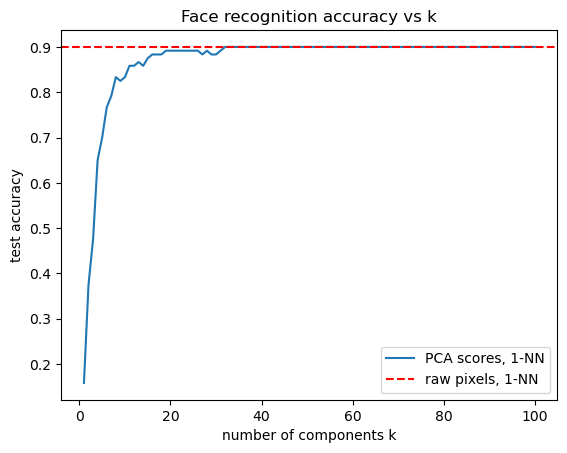

In [23]:
import matplotlib.pyplot as plt

plt.plot(ks, accs, label="PCA scores, 1-NN")
plt.axhline(acc_raw, color="red", linestyle="--", label="raw pixels, 1-NN")
plt.xlabel("number of components k")
plt.ylabel("test accuracy")
plt.title("Face recognition accuracy vs k")
plt.legend()
plt.show()

$\mu$ and $U$ must be computed from the training set to prevent data leakage from the test set. The test set has to be completely unseen data (not used for training) to simulate how the model will perform in the "real world". If information from the test set is used during preprocessing or feature extraction, the test faces would help choose the directions, meaning they would no longer be truly unseen, and the test accuracy would be optimistically biased.

# B2.4 Distance from face space.
For an image $x$, the *residual* $r(x)=\lVert(I-U_kU_k^T)(x-\mu)\rVert$ measures how far $x$ is from the subspace spanned by the first $k$ eignfaces. Fix $k=50$.

#### a) Compute the residual $r$ for the $120$ test faces, for at least $20$ non-face images, and for a few images of random noise. For the non-faces. cut $64 × 64$ patches from the photos in `sklearn.datasets.load_sample_images` (converted to greyscale and scaled to $[0, 1]$; include some patches from smooth regions, such as the sky. Plot histograms of the residuals.

In [24]:
def compute_residuals(X_images, mean_face, U_k):
    # X_images: shape (4096, N) - flattened images (pixels x samples)
    X_centered = X_images - mean_face[:, np.newaxis]
    
    # Project onto face space: U_k^T * (x - mu) -> shape (k, N)
    projections = U_k.T @ X_centered
    
    # Reconstruct back in image space: U_k * projections -> shape (4096, N)
    reconstructions = U_k @ projections
    
    # Residual vector: (x - mu) - reconstruction
    residual_vectors = X_centered - reconstructions
    
    # Euclidean norm (L2 norm) for each image
    residuals = np.linalg.norm(residual_vectors, axis=0)
    return residuals, reconstructions + mean_face[:, np.newaxis]    

In [25]:
k = 50
U50 = U[:, :k]
r_faces, recon_faces = compute_residuals(X_test.T, mu, U50) # 120 values

In [26]:
from sklearn.datasets import load_sample_images
imgs = load_sample_images().images # two colour photos
grey = [im.mean(axis=2) / 255.0 for im in imgs] # greyscale scaled to [0,1]

rng = np.random.default_rng(0)
patches = []
for _ in range(25):
    g = grey[rng.integers(len(grey))]
    i = rng.integers(0, g.shape[0] - 64)
    j = rng.integers(0, g.shape[1] - 64)
    patches.append(g[i:i+64, j:j+64].reshape(-1))

In [27]:
noise = rng.random((4096, 5))

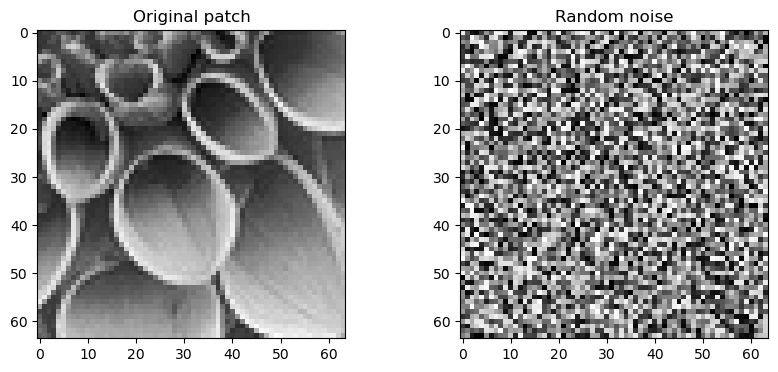

In [28]:
plt.figure(figsize=(10, 4))	
plt.subplot(1, 2, 1)
plt.imshow(patches[0].reshape(64, 64), cmap="gray")
plt.title("Original patch")
plt.subplot(1, 2, 2)
plt.imshow(noise[:, 0].reshape(64, 64), cmap="gray")
plt.title("Random noise")
plt.show()

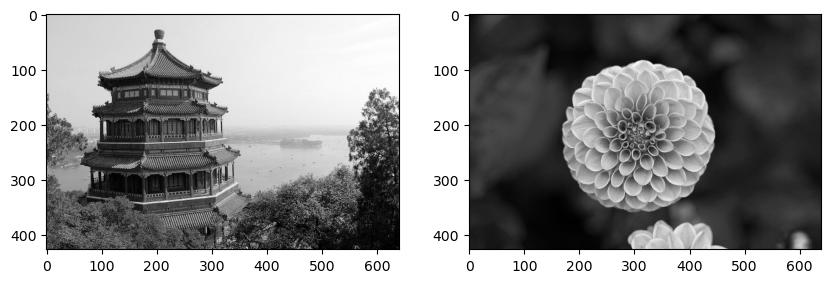

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, g in zip(axs, grey):
    ax.imshow(g, cmap="gray")
plt.show()

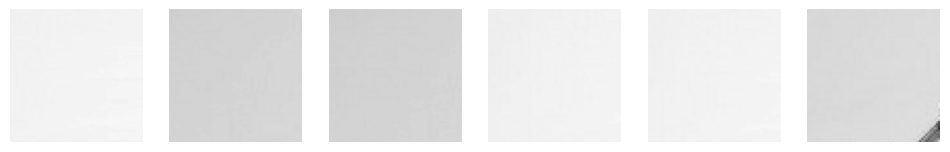

In [30]:
sky = []
g = grey[0]
for _ in range(6):
    i = rng.integers(0, 20)               
    j = rng.choice([rng.integers(0, 130),
                    rng.integers(340, 440)])
    sky.append(g[i:i+64, j:j+64].reshape(-1))

fig, axs = plt.subplots(1, 6, figsize=(12, 2))
for ax, p in zip(axs, sky):
    ax.imshow(p.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

In [31]:
nonfaces = np.column_stack(patches + sky)
r_nonfaces, recon_nonfaces = compute_residuals(nonfaces, mu, U50)
r_noise, recon_noise = compute_residuals(noise, mu, U50)

print("sky residuals:   ", np.round(r_nonfaces[-6:], 2))
print("random patches:  ", np.round(np.sort(r_nonfaces[:-6]), 2))
print("face range:      ", r_faces.min().round(2), r_faces.max().round(2))

sky residuals:    [4.43 3.68 3.66 4.38 4.4  4.13]
random patches:   [ 2.79  2.82  2.99  2.99  3.01  3.06  3.35  3.53  3.67  3.79  3.84  4.05
  4.22  5.03  5.31  6.35  7.22  7.24  7.56  8.39  8.59  8.63  9.19 11.67
 12.7 ]
face range:       2.4 6.24


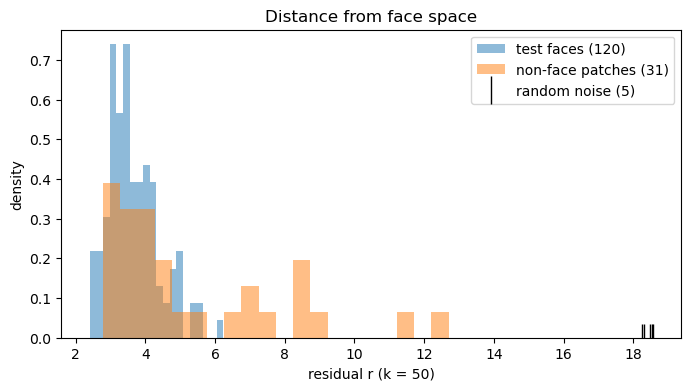

In [32]:
plt.figure(figsize=(8, 4))
plt.hist(r_faces, bins=20, density=True, alpha=0.5, label="test faces (120)")
plt.hist(r_nonfaces, bins=20, density=True, alpha=0.5, label="non-face patches (31)")
plt.plot(r_noise, np.zeros_like(r_noise), "k|", markersize=20, label="random noise (5)")
plt.xlabel("residual r (k = 50)")
plt.ylabel("density")
plt.title("Distance from face space")
plt.legend()
plt.show()

In [33]:
print("faces     r: min %.1f mean %.1f max %.1f" % (r_faces.min(), r_faces.mean(), r_faces.max()))
print("non-faces r: min %.1f mean %.1f max %.1f" % (r_nonfaces.min(), r_nonfaces.mean(), r_nonfaces.max()))
print("noise     r: mean %.1f" % r_noise.mean())
print("non-faces inside face range:", (r_nonfaces <= r_faces.max()).sum(), "/", len(r_nonfaces))

faces     r: min 2.4 mean 3.7 max 6.2
non-faces r: min 2.8 mean 5.4 max 12.7
noise     r: mean 18.4
non-faces inside face range: 21 / 31


The figure above shows the residuals for $k = 50$. Test faces have small residuals, from $2.4$ to $6.2$, because the eigenfaces were built from faces. On average, the non face patches have larger residuals (mean $12.7$), but $21$ of the $31$ fall within the range of the faces, including the smooth sky patches, which means that $r$ alone can't reliably tell faces from non faces. Random noise has a much larger residual, about $18.4$, which is far outside the face range.

#### b) Some non-face images have residuals as small as those of faces. Display a few of them alongside their projections onto face space. Explain geometrically why these images lie close to face space, while random noise does not.

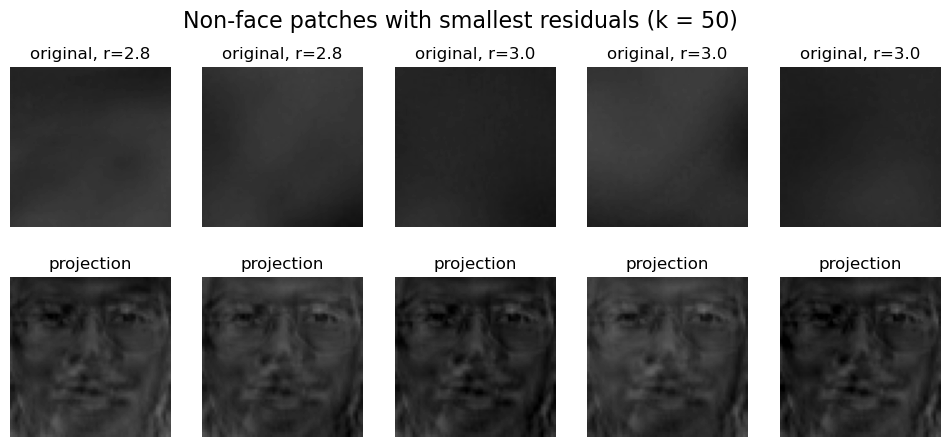

In [34]:
inside = np.where(r_nonfaces <= r_faces.max())[0]
pick = inside[np.argsort(r_nonfaces[inside])][:5]

fig, axs = plt.subplots(2, 5, figsize=(12, 5))
for c, idx in enumerate(pick):
    axs[0, c].imshow(nonfaces[:, idx].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axs[0, c].set_title(f"original, r={r_nonfaces[idx]:.1f}")
    axs[1, c].imshow(recon_nonfaces[:, idx].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axs[1, c].set_title("projection")
    axs[0, c].axis("off"); axs[1, c].axis("off")
fig.suptitle("Non-face patches with smallest residuals (k = 50)", fontsize=16)
plt.show()

The face space is the $50$ dimensional subspace that is spanned by the first $50$ eigenfaces, and the residual is the length of the part $x - \mu$ that is orthagonal to that subspace. Some of the non-face images- such as the smoother patches with subtle changes in brightness, can have small residuals because their pixel patterns may be approximated reasonably well by combinations of the leading eigenfaces. The residual measures similarity to the subspace. Random noise has its noise spread evenly over all $4096 (64 \times 64)$ directions, and a $50$ dimensional subspace only captures a very small amount of that, which leaves a large residual. 

#### c) Suggest a second test that, combined with $r$, would reject these images while still accepting faces, and check how well the combination works as a face detector.

In [35]:
def score_norm(X_cols):                       # images as columns
    return np.linalg.norm(U50.T @ (X_cols - mu[:, None]), axis=0)

s_train = score_norm(X_train.T)
s_faces = score_norm(X_test.T)
s_non   = score_norm(nonfaces)
s_noise = score_norm(noise)

r_train, _ = compute_residuals(X_train.T, mu, U50)

# thresholds from training faces only
tau_r = np.percentile(r_train, 95)
tau_s = np.percentile(s_train, 95)

def accept_r(r):      return r < tau_r
def accept_both(r, s): return (r < tau_r) & (s < tau_s)

for name, r, s in [("test faces", r_faces, s_faces),
                   ("non-faces", r_nonfaces, s_non),
                   ("noise", r_noise, s_noise)]:
    print(f"{name:10s}  r only: {accept_r(r).mean():.2f}   r and score: {accept_both(r, s).mean():.2f}")

test faces  r only: 0.61   r and score: 0.58
non-faces   r only: 0.35   r and score: 0.00
noise       r only: 0.00   r and score: 0.00


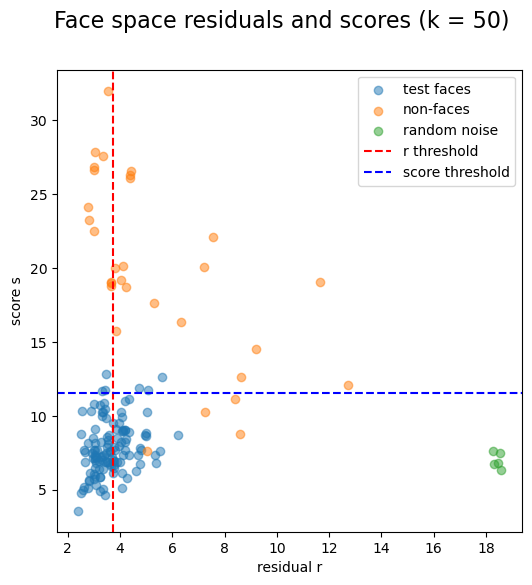

In [36]:
# scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(r_faces, s_faces, label="test faces", alpha=0.5)
plt.scatter(r_nonfaces, s_non, label="non-faces", alpha=0.5)
plt.scatter(r_noise, s_noise, label="random noise", alpha=0.5)
plt.axvline(tau_r, color="red", linestyle="--", label="r threshold")
plt.axhline(tau_s, color="blue", linestyle="--", label="score threshold")
plt.suptitle("Face space residuals and scores (k = 50)", fontsize=16)
plt.xlabel("residual r")
plt.ylabel("score s")
plt.legend()
plt.show()

The residual $r$ only measures the distance from the face space, not if an image is a face. Using the score norm $s(x) = \lVert U_k^T(x - \mu)\rVert$, we are able to measure how far the image is from the mean of the faces within the face space. Faces land at moderate distances, and smooth patches will land further out because $x-\mu$ for a bright or dark patch is a long vector that will lay almost entirely inside of the face space. We will accept an image as a face if $r < \tau_r$ and $s < \tau_s$. Both thresholds $\tau_r$, and $\tau_s$ are the $95th$ percentile of the training faces $r$ and $s$ values, which tells us that none of the test data influenced them.

With $r$ alone, $\approx32\%$ of the non face images are accepted. By adding the score test, we can reduce this to $0\%$, while test faces accepted only falls from $61\%$ to $58\%$. Looking at the above scatter plot we can see non faces with small residual (left of the red line) have scores that are far above the blue line, while nearly all test faces fall below it. The random noise has a smaller score similar to the test faces, but a much larger residual, so it is rejected by $r$ alone, which is why both tests are needed.